In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 03 — Training: U-Net (ResNet-34) on Sentinel-1 patches

Runs on the **university JupyterLab GPU**.

**Run notebooks 01 and 02 on this server first.** They create the files below.

**Files needed in the same folder as this notebook:**
```
03_training.ipynb
preprocess.py
data/
  patches/train/*.npz   patches/val/*.npz   patches/test/*.npz
  patch_index.csv
  norm_stats.json
```

**Output** (in `runs/<VARIANT>/`): `best.pth` (best validation mIoU), `last.pth` (for resuming), `history.csv`, `curves.png`, `config.json`, `val_per_class.csv`.

If the browser tab closes or the session times out: re-open, run all cells again — training **resumes** from the last finished epoch.

## 0. Check the data from notebooks 01 and 02

In [1]:
import glob, os
for sp in ["train", "val", "test"]:
    print(sp, len(glob.glob(f"data/patches/{sp}/*.npz")), "patches")
print("patch_index.csv:", os.path.exists("data/patch_index.csv"),
      "| norm_stats.json:", os.path.exists("data/norm_stats.json"))

train 700 patches
val 64 patches
test 96 patches
patch_index.csv: True | norm_stats.json: True


## 1. Setup and GPU check

In [2]:
# Installs only what is missing (into your user environment on the server)
import importlib, subprocess, sys
for pkg, mod in [("segmentation-models-pytorch", "segmentation_models_pytorch"), ("pandas", "pandas"),
                 ("matplotlib", "matplotlib"), ("tqdm", "tqdm")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "-q", "--no-warn-script-location", pkg])
print("packages ok")

packages ok



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [3]:
import json, random, time
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

sys.path.append(".")
from preprocess import CLASSES, IGNORE, load_stats

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", dev)
if dev == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}, {p.total_memory / 1e9:.1f} GB")
else:
    print("WARNING: no GPU found - training will be very slow. Check the JupyterLab server/kernel has a GPU.")

torch 2.9.1+cu128 | device: cuda
GPU: NVIDIA RTX A6000, 50.9 GB


## 2. Settings

Change **one thing per variant** and give it a new `VARIANT` name, so runs never overwrite each other:

| VARIANT | change |
|---|---|
| `A_baseline` | round 1 (18 training regions) — already done |
| `A_round2` | as below: same settings, 28 training regions |
| `B_no_pretrain` | `ENCODER_WEIGHTS = None` |
| `C_median_filter` | re-run notebook 02 with `SPECKLE_FILTER = True` into a separate data folder, set `DATA` to it |
| `D_no_weights` | `USE_CLASS_WEIGHTS = False`, `USE_DICE = False` |

In [4]:
import torch.multiprocessing as mp
mp.set_sharing_strategy("file_system")   # the server has little shared memory (/dev/shm)

CFG = dict(
    VARIANT           = "A_round2",
    DATA              = "data",
    ENCODER           = "resnet34",
    ENCODER_WEIGHTS   = "imagenet",     # None = random start
    EPOCHS            = 40,
    BATCH_SIZE        = 16,             # lower to 8 if "CUDA out of memory"
    LR                = 3e-4,
    WEIGHT_DECAY      = 1e-4,
    PATIENCE          = 8,              # stop if val mIoU does not improve for 8 epochs
    USE_CLASS_WEIGHTS = True,
    USE_DICE          = True,
    NUM_WORKERS       = 2,              # set 0 if you get "shared memory" / worker errors
    SEED              = 42,
)
RUN  = Path("runs") / CFG["VARIANT"]; RUN.mkdir(parents=True, exist_ok=True)
DATA = Path(CFG["DATA"])
json.dump(CFG, open(RUN / "config.json", "w"), indent=2)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])
NC = len(CLASSES)

## 3. Data

* **Training:** each time a patch is used, one **random month** is picked (teaches the model every season), then random flips / 90° rotations and a small ±1 dB offset per band.
* **Validation:** every patch × all 12 months, no augmentation. Kept in memory for speed.
* Pixels without radar data in that month become *ignore* (255). Inputs are normalised with `norm_stats.json` (training statistics).

In [5]:
stats = load_stats(DATA / "norm_stats.json")
index = pd.read_csv(DATA / "patch_index.csv")
index["file"] = index["file"].str.replace("\\", "/", regex=False)   # Windows paths -> Linux paths
MEAN = np.array(stats["mean"], np.float32)[:, None, None]
STD  = np.array(stats["std"],  np.float32)[:, None, None]

def prep(x, y):
    # x: (3, H, W) clipped dB with NaN; y: (H, W) -> normalised x, y with no-data = ignore
    y = np.where(np.isnan(x).any(0), IGNORE, y)
    x = np.nan_to_num((x - MEAN) / STD, nan=0.0)
    return x.astype(np.float32), y.astype(np.int64)

class TrainPatches(Dataset):
    def __init__(self, files): self.files = list(files)
    def __len__(self): return len(self.files)
    def __getitem__(self, k):
        d = np.load(DATA / self.files[k])
        m = random.randrange(12)
        x, y = d["x"][m].astype(np.float32), d["y"]
        x = x + np.random.uniform(-1, 1, (3, 1, 1)).astype(np.float32)      # ±1 dB offset
        if random.random() < 0.5: x, y = x[:, :, ::-1], y[:, ::-1]
        if random.random() < 0.5: x, y = x[:, ::-1], y[::-1]
        r = random.randrange(4); x, y = np.rot90(x, r, (1, 2)), np.rot90(y, r)
        x, y = prep(np.ascontiguousarray(x), np.ascontiguousarray(y))
        return torch.from_numpy(x), torch.from_numpy(y)

class EvalPatches(Dataset):          # all patches x all 12 months, preloaded
    def __init__(self, files):
        self.xs, self.ys = [], []
        for f in tqdm(list(files), desc="loading val"):
            d = np.load(DATA / f)
            for m in range(12):
                x, y = prep(d["x"][m].astype(np.float32), d["y"])
                self.xs.append(torch.from_numpy(x).half()); self.ys.append(torch.from_numpy(y).to(torch.uint8))
    def __len__(self): return len(self.xs)
    def __getitem__(self, k): return self.xs[k].float(), self.ys[k].long()

train_files = index[index.split == "train"].file
val_files   = index[index.split == "val"].file
train_ds, val_ds = TrainPatches(train_files), EvalPatches(val_files)
train_dl = DataLoader(train_ds, CFG["BATCH_SIZE"], shuffle=True, drop_last=True,
                      num_workers=CFG["NUM_WORKERS"], pin_memory=(dev == "cuda"),
                      persistent_workers=CFG["NUM_WORKERS"] > 0)
val_dl   = DataLoader(val_ds, 32, shuffle=False)
print(f"train patches {len(train_ds)}  | val samples {len(val_ds)} ({len(val_files)} patches x 12 months)")

x, y = next(iter(train_dl))
print("batch x", tuple(x.shape), x.dtype, "| y", tuple(y.shape), "| labels present:", sorted(torch.unique(y).tolist()))

loading val:   0%|          | 0/64 [00:00<?, ?it/s]

train patches 700  | val samples 768 (64 patches x 12 months)
batch x (16, 3, 256, 256) torch.float32 | y (16, 256, 256) | labels present: [0, 1, 2, 3, 4, 5, 6, 255]


## 4. Model and loss

* **U-Net** with a **ResNet-34 encoder**: the encoder learns *what* is in the patch, the decoder restores full resolution to say *where*, skip connections keep edges sharp.
* Input: 3 channels (VV, VH, VV−VH). The ImageNet first layer is adapted to 3 radar channels automatically.
* **Loss = weighted cross-entropy + Dice**: cross-entropy for per-pixel accuracy, class weights and Dice so rare classes (Wetland, Bare) are not ignored. Ignore pixels (255) are excluded.

In [6]:
def make_model(weights):
    return smp.Unet(encoder_name=CFG["ENCODER"], encoder_weights=weights, in_channels=3, classes=NC)

try:
    model = make_model(CFG["ENCODER_WEIGHTS"])
except Exception as e:      # e.g. server has no internet to download ImageNet weights
    print("Could not load pretrained weights -> random start. Reason:", str(e)[:120])
    CFG["ENCODER_WEIGHTS"] = None; json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
    model = make_model(None)
model = model.to(dev)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M | encoder weights: {CFG['ENCODER_WEIGHTS']}")

cw = torch.tensor(stats["class_weights"], dtype=torch.float32, device=dev) if CFG["USE_CLASS_WEIGHTS"] else None
ce   = nn.CrossEntropyLoss(weight=cw, ignore_index=IGNORE)
dice = smp.losses.DiceLoss("multiclass", ignore_index=IGNORE)
def loss_fn(out, y):
    out = out.float()
    return ce(out, y) + (dice(out, y) if CFG["USE_DICE"] else 0.0)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

parameters: 24.4 M | encoder weights: imagenet


In [7]:
def confusion(pred, y):
    k = y != IGNORE
    return torch.bincount(y[k] * NC + pred[k], minlength=NC * NC).reshape(NC, NC)

def scores(cm):
    cm = cm.double(); tp = cm.diag()
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).clamp(min=1)
    f1  = 2 * tp / (cm.sum(0) + cm.sum(1)).clamp(min=1)
    return (tp.sum() / cm.sum()).item(), iou.cpu().numpy(), f1.cpu().numpy()

@torch.no_grad()
def evaluate(m, dl):
    m.eval(); total, n = 0.0, 0
    cm = torch.zeros(NC, NC, dtype=torch.long, device=dev)
    for x, y in dl:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
            out = m(x)
        total += loss_fn(out, y).item() * len(x); n += len(x)
        cm += confusion(out.argmax(1), y)
    oa, iou, f1 = scores(cm)
    return total / n, oa, iou, f1, cm

## 5. Sanity check: can the model memorise one batch?

Trains a **copy** of the model on a single batch for 60 steps. The loss should drop a lot (e.g. from ~3 to < 0.5).
If it does not, something is wrong with the data or labels — fix that before the real training.

In [8]:
import copy
tmp = copy.deepcopy(model).train()
opt_tmp = torch.optim.AdamW(tmp.parameters(), lr=1e-3)
xb, yb = x.to(dev), y.to(dev)
for step in range(60):
    l = loss_fn(tmp(xb), yb); opt_tmp.zero_grad(); l.backward(); opt_tmp.step()
    if step % 10 == 0 or step == 59: print(f"step {step:2d}  loss {l.item():.3f}")
del tmp, opt_tmp
if dev == "cuda": torch.cuda.empty_cache()

step  0  loss 2.950
step 10  loss 1.480
step 20  loss 0.975
step 30  loss 0.713
step 40  loss 0.595
step 50  loss 0.504
step 59  loss 0.457


## 6. Training (resumes automatically)

Each epoch prints train loss, val loss, val OA and val mIoU. `best.pth` is saved whenever val mIoU improves; `last.pth` after every epoch.

In [9]:
opt    = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
sched  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["EPOCHS"])
scaler = torch.amp.GradScaler("cuda", enabled=(dev == "cuda"))
start, history, best, bad = 0, [], -1.0, 0

if (RUN / "last.pth").exists():                                  # resume
    ck = torch.load(RUN / "last.pth", map_location=dev, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start, history, best, bad = ck["epoch"] + 1, ck["history"], ck["best"], ck["bad"]
    print(f"Resuming from epoch {start}  (best val mIoU so far {best:.4f})")

for epoch in range(start, CFG["EPOCHS"]):
    if bad >= CFG["PATIENCE"]:
        print("Early stopping."); break
    t0 = time.time(); model.train(); tl, n = 0.0, 0
    for x, y in tqdm(train_dl, desc=f"epoch {epoch}", leave=False):
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
            out = model(x)
        loss = loss_fn(out, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tl += loss.item() * len(x); n += len(x)
    sched.step()

    vl, oa, iou, f1, _ = evaluate(model, val_dl)
    row = dict(epoch=epoch, train_loss=tl / n, val_loss=vl, val_oa=oa, val_miou=float(iou.mean()),
               lr=opt.param_groups[0]["lr"], seconds=time.time() - t0)
    history.append(row)
    improved = row["val_miou"] > best
    if improved:
        best, bad = row["val_miou"], 0
        torch.save(model.state_dict(), RUN / "best.pth")
    else:
        bad += 1
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    scaler=scaler.state_dict(), epoch=epoch, history=history, best=best, bad=bad),
               RUN / "last.pth")
    pd.DataFrame(history).to_csv(RUN / "history.csv", index=False)
    print(f"ep {epoch:2d} | train {row['train_loss']:.3f} | val {vl:.3f} | OA {oa:.3f} | "
          f"mIoU {row['val_miou']:.3f}{'  *best*' if improved else ''} | {row['seconds']:.0f}s")
print(f"Done. Best val mIoU: {best:.4f}")

epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

ep  0 | train 2.264 | val 2.344 | OA 0.545 | mIoU 0.268  *best* | 12s


epoch 1:   0%|          | 0/43 [00:00<?, ?it/s]

ep  1 | train 1.845 | val 2.122 | OA 0.544 | mIoU 0.273  *best* | 11s


epoch 2:   0%|          | 0/43 [00:00<?, ?it/s]

ep  2 | train 1.706 | val 1.866 | OA 0.609 | mIoU 0.370  *best* | 11s


... (62 outputs left out)

epoch 34:   0%|          | 0/43 [00:00<?, ?it/s]

ep 34 | train 0.900 | val 1.599 | OA 0.697 | mIoU 0.471 | 12s


epoch 35:   0%|          | 0/43 [00:00<?, ?it/s]

ep 35 | train 0.843 | val 1.571 | OA 0.699 | mIoU 0.480 | 12s
Early stopping.
Done. Best val mIoU: 0.5081


## 7. Training curves (needed in the report)

* **Healthy:** both losses fall, val mIoU rises then flattens.
* **Overfitting:** train loss keeps falling while val loss rises → more regions / augmentation / earlier stop.
* **Underfitting:** both losses stay high → train longer, check data.

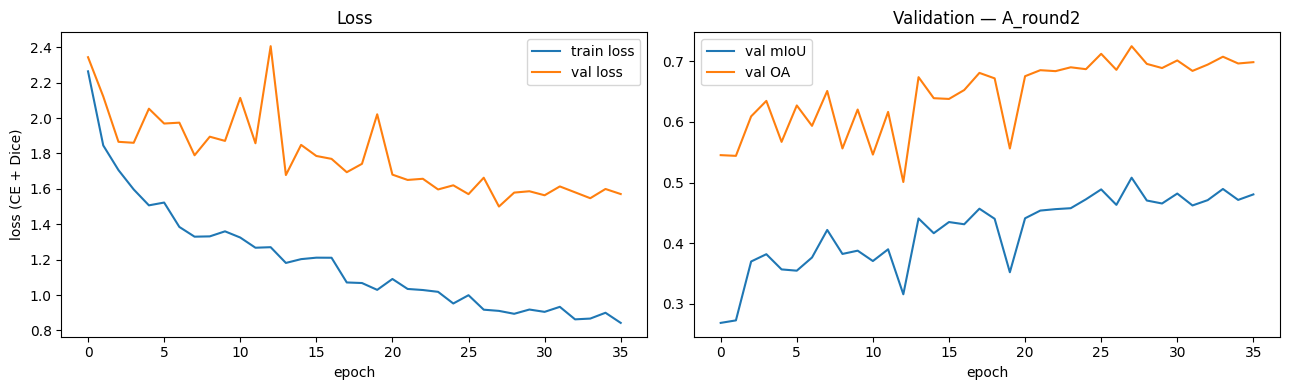

In [10]:
h = pd.read_csv(RUN / "history.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h.epoch, h.train_loss, label="train loss"); ax[0].plot(h.epoch, h.val_loss, label="val loss")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss (CE + Dice)"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(h.epoch, h.val_miou, label="val mIoU"); ax[1].plot(h.epoch, h.val_oa, label="val OA")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title(f"Validation — {CFG['VARIANT']}")
plt.tight_layout(); plt.savefig(RUN / "curves.png", dpi=150); plt.show()

## 8. Best model on the validation set (per class)

The **test set is not touched here** — it is evaluated once, in notebook 04, after you have chosen the final variant using these validation numbers.

A_round2  val OA 0.725  val mIoU 0.508


,IoU,F1
Trees,0.428,0.600
Grass/Shrub,0.301,0.463
Cropland,0.497,0.664
Built-up,0.754,0.860
Bare,0.262,0.416
Water,0.769,0.870
Wetland,0.545,0.706
mean,0.508,0.654


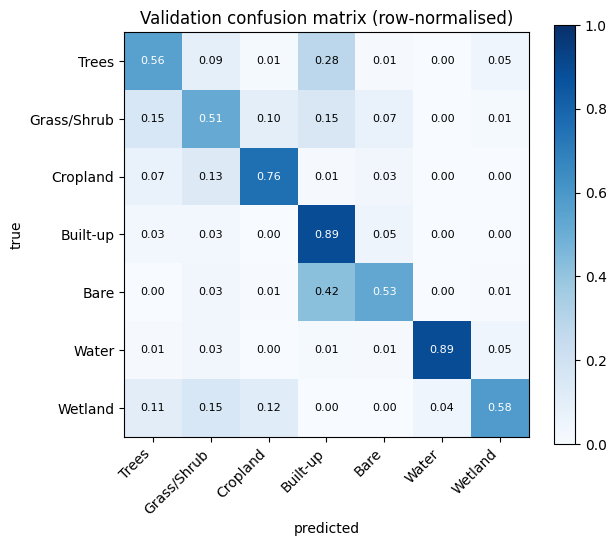

In [11]:
model.load_state_dict(torch.load(RUN / "best.pth", map_location=dev))
vl, oa, iou, f1, cm = evaluate(model, val_dl)
res = pd.DataFrame({"IoU": iou, "F1": f1}, index=CLASSES).round(3)
res.loc["mean"] = res.mean().round(3)
res.to_csv(RUN / "val_per_class.csv")
print(f"{CFG['VARIANT']}  val OA {oa:.3f}  val mIoU {iou.mean():.3f}")
display(res)

cmn = (cm.double() / cm.sum(1, keepdim=True).clamp(min=1)).cpu().numpy()
plt.figure(figsize=(6.5, 5.5)); plt.imshow(cmn, cmap="Blues", vmin=0, vmax=1); plt.colorbar()
plt.xticks(range(NC), CLASSES, rotation=45, ha="right"); plt.yticks(range(NC), CLASSES)
for i in range(NC):
    for j in range(NC):
        plt.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=8,
                 color="white" if cmn[i, j] > 0.5 else "black")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Validation confusion matrix (row-normalised)")
plt.tight_layout(); plt.savefig(RUN / "val_confusion.png", dpi=150); plt.show()

✅ **Download from `runs/<VARIANT>/`** (or zip the folder: `import shutil; shutil.make_archive("A_round2_results", "zip", "runs/A_round2")`): `best.pth`, `history.csv`, `curves.png`, `val_per_class.csv`, `val_confusion.png`, `config.json`.
Before submitting, use *Kernel → Restart and Run All* only if you want to re-train; otherwise just save the notebook so the outputs stay visible.